# BAIT 508 Group Project: Oil & Gas Extraction (SIC Major Group 13)

**Objective.** Analyse US-listed oil & gas extraction firms with financial data (`public_firms.csv`) and 10-K Item 1 text (2020 and 2025). Then examine one firm, EOG Resources, and give it one recommendation.

**Datasets:** `public_firms.csv`, `major_groups.csv`, `2020_10K_item1_full.csv`, `2025_10K_item1_full.csv`, all read from the notebook's working folder.

**Structure**
| Part | Step | Content |
|---|---|---|
| 1 | A | Sector selection and filtering |
| 1 | B | Prices, sales, locations, 2008 crisis, ROA |
| 2 | C | Text cleaning |
| 2 | D | Merge, data-quality screen, keywords, wordclouds |
| 2 | E | Word2vec |
| 2 | F | 2020 vs 2025 comparison |
| 3 | G | EOG Resources vs peers, and one recommendation |

*Units: `sale`, `asset`, `net_income` and `cash` are in USD millions; `prcc_c` is the calendar year-end share price.*

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import re
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from wordcloud import WordCloud
from gensim.models import Word2Vec
import os


## Part 1 — Quantitative analysis

### A. Industry sector selection and data filtering

We chose **Major Group 13: Oil And Gas Extraction**. A firm's major group is the first two digits of its 4-digit SIC code. We compute it as `sic // 100` (integer division) rather than slicing the string: for 3-digit codes such as 100 (crops), string slicing would give "10" (metal mining).

- **Firm-year observations:** unique (`gvkey`, `fyear`) pairs. The `assert` confirms there are no duplicate pairs, so rows equal firm-years.
- **Unique firms:** we count `gvkey`, Compustat's permanent firm identifier. Company names change over time, so `conm` is not a reliable firm key.
- **Full-history firms:** firms observed in all 32 fiscal years from 1994 to 2025.

In [3]:
public_firms = pd.read_csv("public_firms.csv")
major_groups = pd.read_csv("major_groups.csv")

# Integer division, not string slicing: SIC 100 (crops) would otherwise become "10" (metal mining)
public_firms["major_group"] = public_firms["sic"] // 100

SECTOR_CODES = [13]  # Oil And Gas Extraction; 
print(major_groups[major_groups["major_group"].isin(SECTOR_CODES)])

df_og = public_firms[public_firms["major_group"].isin(SECTOR_CODES)].copy()

# a. firm-year observations (verify gvkey-fyear is unique, so rows = firm-years)
assert not df_og.duplicated(["gvkey", "fyear"]).any()
n_firm_years = df_og[["gvkey", "fyear"]].drop_duplicates().shape[0]

# b. unique firms: gvkey is the stable Compustat ID; company names can change over time
n_firms = df_og["gvkey"].nunique()

# c. firms present in every year 1994-2025
n_years_total = public_firms["fyear"].nunique()          # 32
years_per_firm = df_og.groupby("gvkey")["fyear"].nunique()
full_history_ids = years_per_firm[years_per_firm == n_years_total].index
n_full_history = len(full_history_ids)

print(f"Unique firm-year observations: {n_firm_years:,}")
print(f"Unique firms: {n_firms:,}")
print(f"Firms with records in all {n_years_total} years (1994-2025): {n_full_history}")

print(f"\nThe {n_full_history} firms present in every year:")
full_history_names = sorted(df_og.loc[df_og["gvkey"].isin(full_history_ids), "conm"].unique())
for name in full_history_names:
    print(f"  - {name}")

   major_group             description
7           13  Oil And Gas Extraction
Unique firm-year observations: 8,066
Unique firms: 772
Firms with records in all 32 years (1994-2025): 39

The 39 firms present in every year:
  - ALTEX INDUSTRIES INC
  - APA CORP
  - BARNWELL INDUSTRIES
  - BIG SKY INDUSTRIAL INC
  - CONOCOPHILLIPS
  - CORE LABORATORIES INC
  - COTERRA ENERGY INC
  - DAWSON GEOPHYSICAL CO
  - DEVON ENERGY CORP
  - ENI SPA
  - EOG RESOURCES INC
  - EQT CORP
  - EXPAND ENERGY CORP
  - GULFPORT ENERGY CORP
  - HALLIBURTON CO
  - HELMERICH & PAYNE
  - MEXCO ENERGY CORP
  - MURPHY OIL CORP
  - NABORS INDUSTRIES LTD
  - NOBLE CORP PLC
  - OCCIDENTAL PETROLEUM CORP
  - OCEANEERING INTERNATIONAL
  - PATTERSON-UTI ENERGY INC
  - PRIMEENERGY RESOURCES CORP
  - RANGE RESOURCES CORP
  - RESERVE PETROLEUM CO
  - ROYALE ENERGY INC
  - RPC INC
  - SANTOS LTD
  - SLB LTD
  - SM ENERGY CO
  - SUBSEA 7 SA
  - TETRA TECHNOLOGIES INC/DE
  - TRANSOCEAN LTD
  - TRANSPORTADORA DE GAS DEL SU
  - U

### B. Preliminary analysis

Everything in this section uses the filtered sector data from Step A.

- **B1:** top 10 firms by year-end price (`prcc_c`) in 2020 and 2025.
- **B2:** top 10 firms by sales. We read "highest sales in the entire history" as each firm's **single best year**, and each firm appears once. Ranking raw firm-years instead would let ConocoPhillips fill 6 of the 10 slots.
- **B3:** firms per location, counting each `gvkey` once.
- **B4:** average price by year. We plot the median next to the mean because a few high-priced stocks pull the mean up.
- **B5:** the largest percentage price drop from 2007 to 2008, with a robustness check that excludes penny stocks.
- **B6:** ROA = `net_income / asset` for US firms. We exclude rows with zero or missing assets and missing net income. The simple (equal-weighted) mean ROA is printed in the table below, but we don't plot it: firms with near-zero assets dominate it (worst firm-year −3,268×). We plot the asset-weighted mean and the median instead.

Top 10 oil & gas firms by year-end stock price, 2020
                           Company Year-end price ($) Sales ($M) Location
Rank                                                                     
1              AMEN PROPERTIES INC             397.00        1.1      USA
2             RESERVE PETROLEUM CO             142.70        4.1      USA
3     PIONEER NATURAL RESOURCES CO             113.89    7,024.0      USA
4                        CNOOC LTD              91.65   23,642.3      HKG
5              CHENIERE ENERGY INC              60.03    9,358.0      USA
6            NABORS INDUSTRIES LTD              58.23    2,134.0      BMU
7                        HESS CORP              52.79    4,667.0      USA
8                EOG RESOURCES INC              49.87   11,018.0      USA
9           DIAMONDBACK ENERGY INC              48.40    2,813.0      USA
10      PRIMEENERGY RESOURCES CORP              43.17       58.2      USA

Top 10 oil & gas firms by year-end stock price, 2025
     

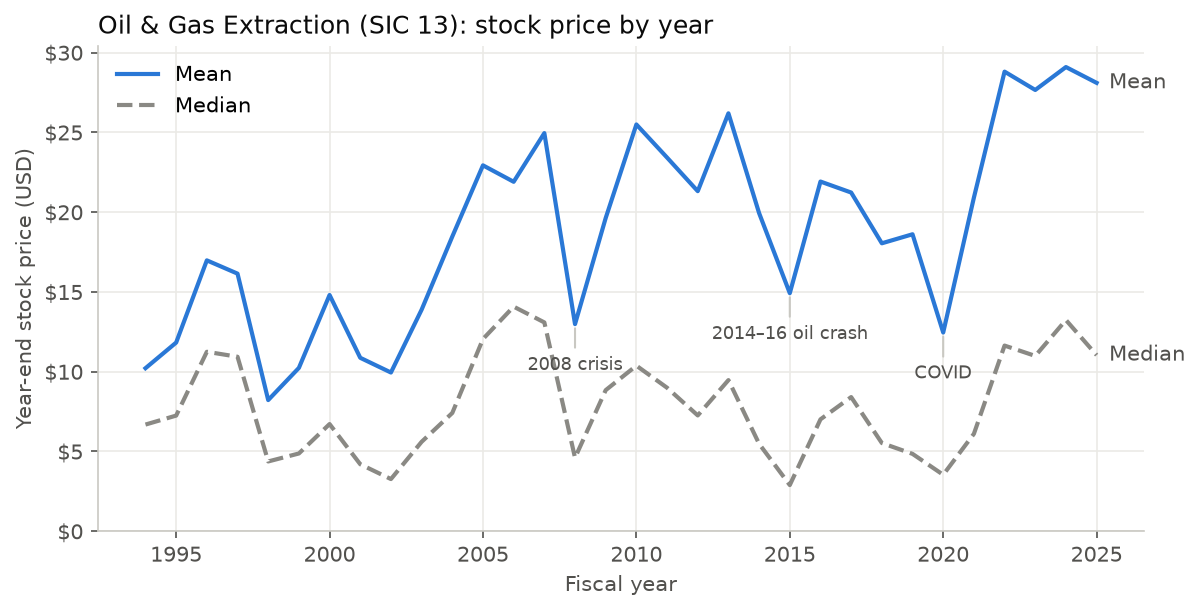

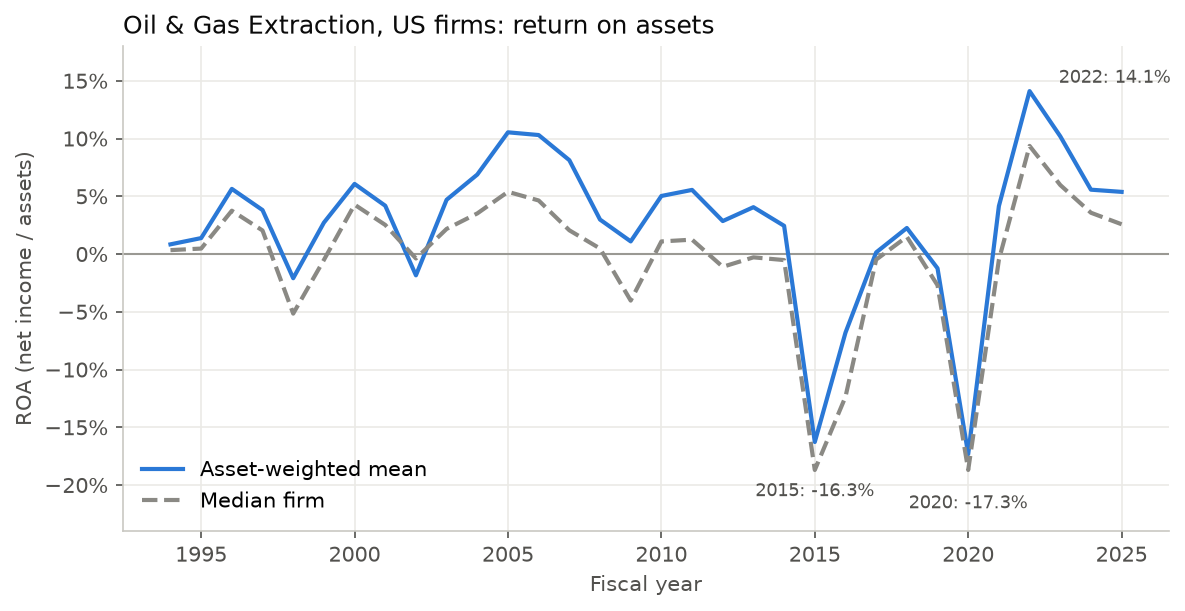

In [7]:
public_firms = pd.read_csv("public_firms.csv")
public_firms["major_group"] = public_firms["sic"] // 100
SECTOR_CODES = [13]
df_og = public_firms[public_firms["major_group"].isin(SECTOR_CODES)].copy()

# Chart style: one hue for the main series, muted grey for the reference series, recessive grid
BLUE, GREY, INK, MUTED = "#2a78d6", "#8a8984", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "figure.dpi": 150, "savefig.bbox": "tight",
})

# ---------- B1. Top 10 stock prices in 2020 and 2025 ----------
cols = ["conm", "prcc_c", "sale", "location"]
top_price_2020 = df_og[df_og["fyear"] == 2020].nlargest(10, "prcc_c")[cols].reset_index(drop=True)
top_price_2025 = df_og[df_og["fyear"] == 2025].nlargest(10, "prcc_c")[cols].reset_index(drop=True)
#print(top_price_2020, top_price_2025, sep="\n\n")

for year, table in [(2020, top_price_2020), (2025, top_price_2025)]:
    display_table = table.rename(columns={
        "conm": "Company",
        "prcc_c": "Year-end price ($)",
        "sale": "Sales ($M)",
        "location": "Location",
    })
    display_table.index = range(1, len(display_table) + 1)   # rank 1-10 instead of 0-9
    display_table.index.name = "Rank"
    print(f"Top 10 oil & gas firms by year-end stock price, {year}")
    print(display_table.to_string(formatters={
        "Year-end price ($)": "{:,.2f}".format,
        "Sales ($M)": "{:,.1f}".format,
    }))
    print()

# ---------- B2. Top 10 firms by sales, all years ----------
# Rank firms, not firm-years: otherwise ConocoPhillips alone fills 6 of the 10 slots
top_sales_firms = (df_og.dropna(subset=["sale"])
                   .sort_values("sale", ascending=False)
                   .drop_duplicates("gvkey")
                   .head(10)[["conm", "fyear", "sale", "location"]]
                   .reset_index(drop=True))
display_sales = top_sales_firms.rename(columns={
    "conm": "Company",
    "fyear": "Peak year",
    "sale": "Peak sales ($M)",
    "location": "Location",
})
display_sales.index = range(1, len(display_sales) + 1)   # rank 1-10 instead of 0-9
display_sales.index.name = "Rank"
print("Top 10 oil & gas firms by highest annual sales, 1994-2025 (each firm's best year)")
print(display_sales.to_string(formatters={"Peak sales ($M)": "{:,.1f}".format}))

# ---------- B3. Geographic distribution ----------
# Count firms, not firm-years; each gvkey has a single location in this file
firm_locations = df_og.drop_duplicates("gvkey")["location"]
top_locations = firm_locations.value_counts().head(10)
#print(top_locations, f"\nUSA share: {(firm_locations == 'USA').mean():.1%}")
location_counts = firm_locations.value_counts()
display_locations = location_counts.head(10).to_frame("Firms")
display_locations["Share of firms"] = display_locations["Firms"] / len(firm_locations)
display_locations.index.name = "Location"
display_locations.insert(0, "Rank", range(1, len(display_locations) + 1))

print(f"Top 10 locations of oil & gas firms ({len(firm_locations)} firms in total)")
print(display_locations.to_string(formatters={"Share of firms": "{:.1%}".format}))

# Flag ties at the cut-off so no location is silently dropped
cutoff = location_counts.iloc[9]
tied = location_counts[location_counts == cutoff].index.tolist()
if len(tied) > 1:
    print(f"\nNote: {', '.join(tied)} are tied with {cutoff} firms each, so 10th place is shared.")

print(f"\nUSA share of all firms: {(firm_locations == 'USA').mean():.1%}")

# ---------- B4. Average stock price by year ----------
price_by_year = df_og.groupby("fyear")["prcc_c"].agg(["mean", "median"])

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(price_by_year.index, price_by_year["mean"], color=BLUE, lw=2, label="Mean")
ax.plot(price_by_year.index, price_by_year["median"], color=GREY, lw=2, ls="--", label="Median")
for col, color in [("mean", BLUE), ("median", GREY)]:
    ax.annotate(col.capitalize(), (price_by_year.index[-1], price_by_year[col].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color=MUTED)
for yr, label in [(2008, "2008 crisis"), (2015, "2014–16 oil crash"), (2020, "COVID")]:
    ax.annotate(label, (yr, price_by_year.loc[yr, "mean"]), xytext=(0, -22),
                textcoords="offset points", ha="center", fontsize=8.5, color=MUTED,
                arrowprops=dict(arrowstyle="-", color="#c9c8c2"))
ax.set_title("Oil & Gas Extraction (SIC 13): stock price by year", loc="left", color=INK)
ax.set_xlabel("Fiscal year")
ax.set_ylabel("Year-end stock price (USD)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_ylim(0, None)
ax.legend(frameon=False, loc="upper left")
fig.savefig("b4_avg_price.png")

# ---------- B5. Biggest 2007 -> 2008 price drop ----------
price_07_08 = (df_og[df_og["fyear"].isin([2007, 2008])]
               .pivot_table(index=["gvkey", "conm"], columns="fyear", values="prcc_c")
               .dropna())
price_07_08 = price_07_08[price_07_08[2007] > 0]   # can't compute % change off a zero base
price_07_08["pct_change"] = (price_07_08[2008] / price_07_08[2007] - 1) * 100
biggest_drops = price_07_08.sort_values("pct_change").head(10)
print(biggest_drops)
print("Median 2007->08 change:", round(price_07_08["pct_change"].median(), 1), "%")

# Robustness check: exclude penny stocks, where tiny price moves create ~100% "drops"
print(price_07_08[price_07_08[2007] >= 5].sort_values("pct_change").head(5))
top = biggest_drops.iloc[0]
robust = price_07_08[price_07_08[2007] >= 5].sort_values("pct_change").iloc[0]
print(f"\nMost affected by the 2008 crisis: {biggest_drops.index[0][1]} "
      f"({top['pct_change']:.2f}%, ${top[2007]:.2f} -> ${top[2008]:.4f}).")
print(f"The 2008 price of ${top[2008]:.4f} may be a data error. Among stocks priced at least $5 "
      f"in 2007, the largest drop was {price_07_08[price_07_08[2007] >= 5].sort_values('pct_change').index[0][1]} "
      f"({robust['pct_change']:.1f}%).")

# ---------- B6. Average ROA, US firms ----------
df_usa = df_og[(df_og["location"] == "USA") & (df_og["asset"] > 0)].dropna(subset=["net_income"]).copy()
df_usa["roa"] = df_usa["net_income"] / df_usa["asset"]

# The equal-weighted mean is dominated by shell companies with near-zero assets
# (worst firm-year: ROA of about -3,268x), so it isn't usable even after winsorizing.
# We plot two averages that hold up: the asset-weighted mean (sector net income /
# sector assets) and the median firm.
roa_by_year = df_usa.groupby("fyear").agg(
    raw_mean=("roa", "mean"), median=("roa", "median"),
    total_ni=("net_income", "sum"), total_assets=("asset", "sum"), n_firms=("roa", "size"))
roa_by_year["asset_weighted"] = roa_by_year["total_ni"] / roa_by_year["total_assets"]
print(roa_by_year[["raw_mean", "asset_weighted", "median", "n_firms"]].round(3))
print(df_usa["roa"].quantile([0.01, 0.05, 0.5, 0.95, 0.99]).round(2))

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.axhline(0, color="#9a9993", lw=1)
ax.plot(roa_by_year.index, roa_by_year["asset_weighted"], color=BLUE, lw=2, label="Asset-weighted mean")
ax.plot(roa_by_year.index, roa_by_year["median"], color=GREY, lw=2, ls="--", label="Median firm")
for yr, label in [(2015, "2015"), (2020, "2020"), (2022, "2022")]:
    v = roa_by_year.loc[yr, "asset_weighted"]
    ax.annotate(f"{label}: {v:.1%}", (yr, v), xytext=(14, 4) if v > 0 else (0, -26),
                textcoords="offset points", ha="left" if v > 0 else "center", fontsize=8.5, color=MUTED)
ax.set_ylim(-0.24, 0.18)
ax.set_title("Oil & Gas Extraction, US firms: return on assets", loc="left", color=INK)
ax.set_xlabel("Fiscal year")
ax.set_ylabel("ROA (net income / assets)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.legend(frameon=False, loc="lower left")
fig.savefig("b6_roa_usa.png")

## Part 2 — Text analysis

### C. Text cleaning (2020 10-K Item 1, full sample)

Following the brief, we lowercase all text, remove punctuation and remove NLTK English stop words. Two implementation choices:
- Punctuation is **replaced with a space**, so "oil-and-gas" becomes "oil and gas" rather than "oilandgas". The regex `[^\w\s]|_` also catches Unicode punctuation (curly quotes, bullets, ®) that `string.punctuation` misses.
- We first drop **329 exact duplicate rows** (same cik, gvkey and text). Otherwise those filings would count twice in word2vec training.

Numbers are kept at this stage, because the brief's cleaning steps do not remove them. They are filtered out later, when building keywords (D) and word2vec sentences (E).

In [4]:
nltk.download("stopwords", quiet=True)
STOP_WORDS = set(stopwords.words("english"))

# [^\w\s] catches Unicode punctuation too (curly quotes, em dashes, bullets, ®),
# which string.punctuation misses; "_" is a word character, so it's added explicitly
PUNCT_RE = re.compile(r"[^\w\s]|_")


def clean_text(text):
    text = text.lower()
    # Replace punctuation with a space rather than deleting it, so "oil-and-gas" -> "oil and gas"
    # instead of "oilandgas". Contractions split into fragments ("don't" -> "don", "t"),
    # and NLTK's list already contains those fragments, so they still get removed.
    text = PUNCT_RE.sub(" ", text)
    return " ".join(w for w in text.split() if w not in STOP_WORDS)


def load_and_clean(path):
    df = pd.read_csv(path)
    # The 2020 file has 329 rows that are exact copies (same cik, gvkey and text). Repeats
    # would double-count those filings in word2vec training, so drop them.
    df = df.drop_duplicates().reset_index(drop=True)
    df["item_1_clean"] = df["item_1"].fillna("").map(clean_text)
    return df


if __name__ == "__main__":
    df_2020 = load_and_clean("2020_10K_item1_full.csv")

    raw_tokens = df_2020["item_1"].str.split().str.len()
    clean_tokens = df_2020["item_1_clean"].str.split().str.len()
    print(df_2020.shape)
    print(f"Tokens per filing (median): raw {raw_tokens.median():,.0f} -> clean {clean_tokens.median():,.0f}")
    print(f"Share of tokens removed: {1 - clean_tokens.sum() / raw_tokens.sum():.1%}")
    print(df_2020[["name", "item_1_clean"]].head())

    # Saved so Parts D/E don't redo a few minutes of cleaning each time
    df_2020.to_pickle("df_2020_clean.pkl")

(5152, 6)
Tokens per filing (median): raw 6,326 -> clean 4,063
Share of tokens removed: 36.3%
                        name  \
0           ACCESS-POWER INC   
1        HURCO COMPANIES INC   
2  ACRO BIOMEDICAL CO., LTD.   
3     Chun Can Capital Group   
4    Adaiah Distribution Inc   

                                        item_1_clean  
0  fixed expenses previosuly documented 8k 2 350 ...  
1  general hurco companies inc international indu...  
2  engaged business developing marketing products...  
3  corporate history chun capital group formerly ...  
4  general adaiah distribution inc incorporated s...  


### D. Keyword analysis (2020)

**D.1 Merge and merge key.** We inner-join the 10-K data to `public_firms.csv` on **`gvkey`**, Compustat's permanent firm identifier, which exists in both files.
- *Why not cik:* in the 10-K file, 285 ciks map to more than one gvkey (e.g. Arconic).
- *Why not names:* names are formatted differently in the two files ("DEVON ENERGY CORP/DE" vs "DEVON ENERGY CORP").

Because `public_firms.csv` has one row per firm-year, we first reduce it to **one row per firm**, keeping the fiscal year closest to 2020. Firms with two or more different filings keep the **longest** one (the full Item 1, not a stub).

**Data-quality screen.** After the merge, we found that **about 1 in 4 oil & gas rows in the 2020 file contain another company's Item 1 text**. For example, ConocoPhillips' row is SunPower's business description, Marathon Oil's is Hershey's, and Hess's is CVR Energy's. Keeping these rows would give such firms keywords like "solar", "chocolate" or "fertilizer". We flag a filing as mismatched when the distinctive word in the firm's name never appears in its own text. We then read every flagged row by hand, plus every row with fewer than 10 oil & gas words per 1,000. The dropped rows are saved to `d_dropped_mismatched_2020.csv`.

**D.2 Keywords.** We use letters-only tokens of 2 or more characters, which removes numbers and stray letters.
- **Word counts:** fitted on the sector filings.
- **TF-IDF:** the IDF is fitted on the **full 10-K corpus (all industries)**. A word then scores high when it is frequent for the firm *and* rare across public companies, so the keywords show what sets oil & gas firms apart from other industries. `min_df=5` keeps one-off typos from getting the maximum IDF.

**D.3 Wordclouds.** Each word's weight is its D.2 score summed over every firm whose top 10 it appears in, so the clouds show exactly the D.2 keywords.

Merged rows (one per firm): 159
Firms whose kept row is fyear 2020: 129
Low-vocabulary rows for manual review:
                                       name  og_words_per_1k
52                        PDC ENERGY, INC.              1.9
54                        Berry Corp (bry)              3.8
96              Extraction Oil & Gas, Inc.              2.2
65          OCCIDENTAL PETROLEUM CORP /DE/              4.7
5                           HALLIBURTON CO              7.7
35            Select Energy Services, Inc.              5.2
34                   NABORS INDUSTRIES LTD              2.0
14                          CONOCOPHILLIPS              2.4
66                                 RPC INC              1.3
79                 GOODRICH PETROLEUM CORP              2.6
20                            SM Energy Co              4.0
136                     LILIS ENERGY, INC.              4.0
93                       TALOS ENERGY INC.              1.9
23                       Hess Midstream LP      

,gvkey,conm,sic,top10_count,top10_tfidf
0,187128,WPX ENERGY INC,1311,"may, gas, oil, natural, could, operations, res...","felix, gas, oil, fracturing, reserves, natural..."
1,187812,MATADOR RESOURCES CO,1311,"oil, gas, natural, production, december, wells...","oil, gas, natural, mateo, proved, wells, bbl, ..."
2,184442,CHORD ENERGY CORP,1311,"gas, oil, natural, crude, production, wells, b...","crude, gas, oil, natural, basin, wells, omp, w..."
3,170750,DIAMONDBACK ENERGY INC,1311,"oil, gas, natural, wells, production, basin, m...","oil, gas, natural, wells, basin, drilling, per..."
4,21834,MAMMOTH ENERGY SERVICES INC,1389,"services, drilling, oil, natural, operations, ...","drilling, fracturing, sand, oil, services, unc..."
5,186276,KOSMOS ENERGY LTD,1311,"oil, gas, production, well, exploration, devel...","mauritania, senegal, exploration, offshore, pr..."
6,187698,CIVITAS RESOURCES INC,1311,"gas, oil, natural, operations, december, regul...","gas, oil, natural, proved, wells, reserves, dr..."
7,9904,SOUTHWESTERN ENERGY CO,1311,"gas, natural, reserves, oil, production, prove...","gas, proved, reserves, oil, appalachia, bcfe, ..."
8,194755,AMPLIFY ENERGY CORP,1311,"gas, oil, natural, production, operations, may...","oil, gas, wells, fracturing, natural, proved, ..."
9,187961,VITAL ENGY INC,1311,"oil, gas, natural, wells, production, reserves...","oil, wells, gas, fracturing, acreage, proved, ..."


Word count, sector top 20:
 gas            7931
oil            7506
natural        5230
production     3440
operations     3021
services       2226
company        2200
may            1937
wells          1771
reserves       1699
drilling       1425
december       1058
regulations    1049
well            964
customers       812
net             808
properties      725
state           630
proved          527
trust           517
TF-IDF, sector top 20:
 oil           28.85
gas           27.47
drilling      13.46
natural       12.60
wells         11.24
proved         7.43
fracturing     7.42
reserves       5.13
hydraulic      4.14
company        3.74
rigs           3.57
services       3.08
rig            2.44
basin          2.37
subsea         2.36
epa            2.33
seismic        2.23
production     2.06
offshore       1.96
crude          1.95
Firms with term in top 10 (count):
 gas            98
oil            97
operations     67
natural        64
production     63
may            41
well

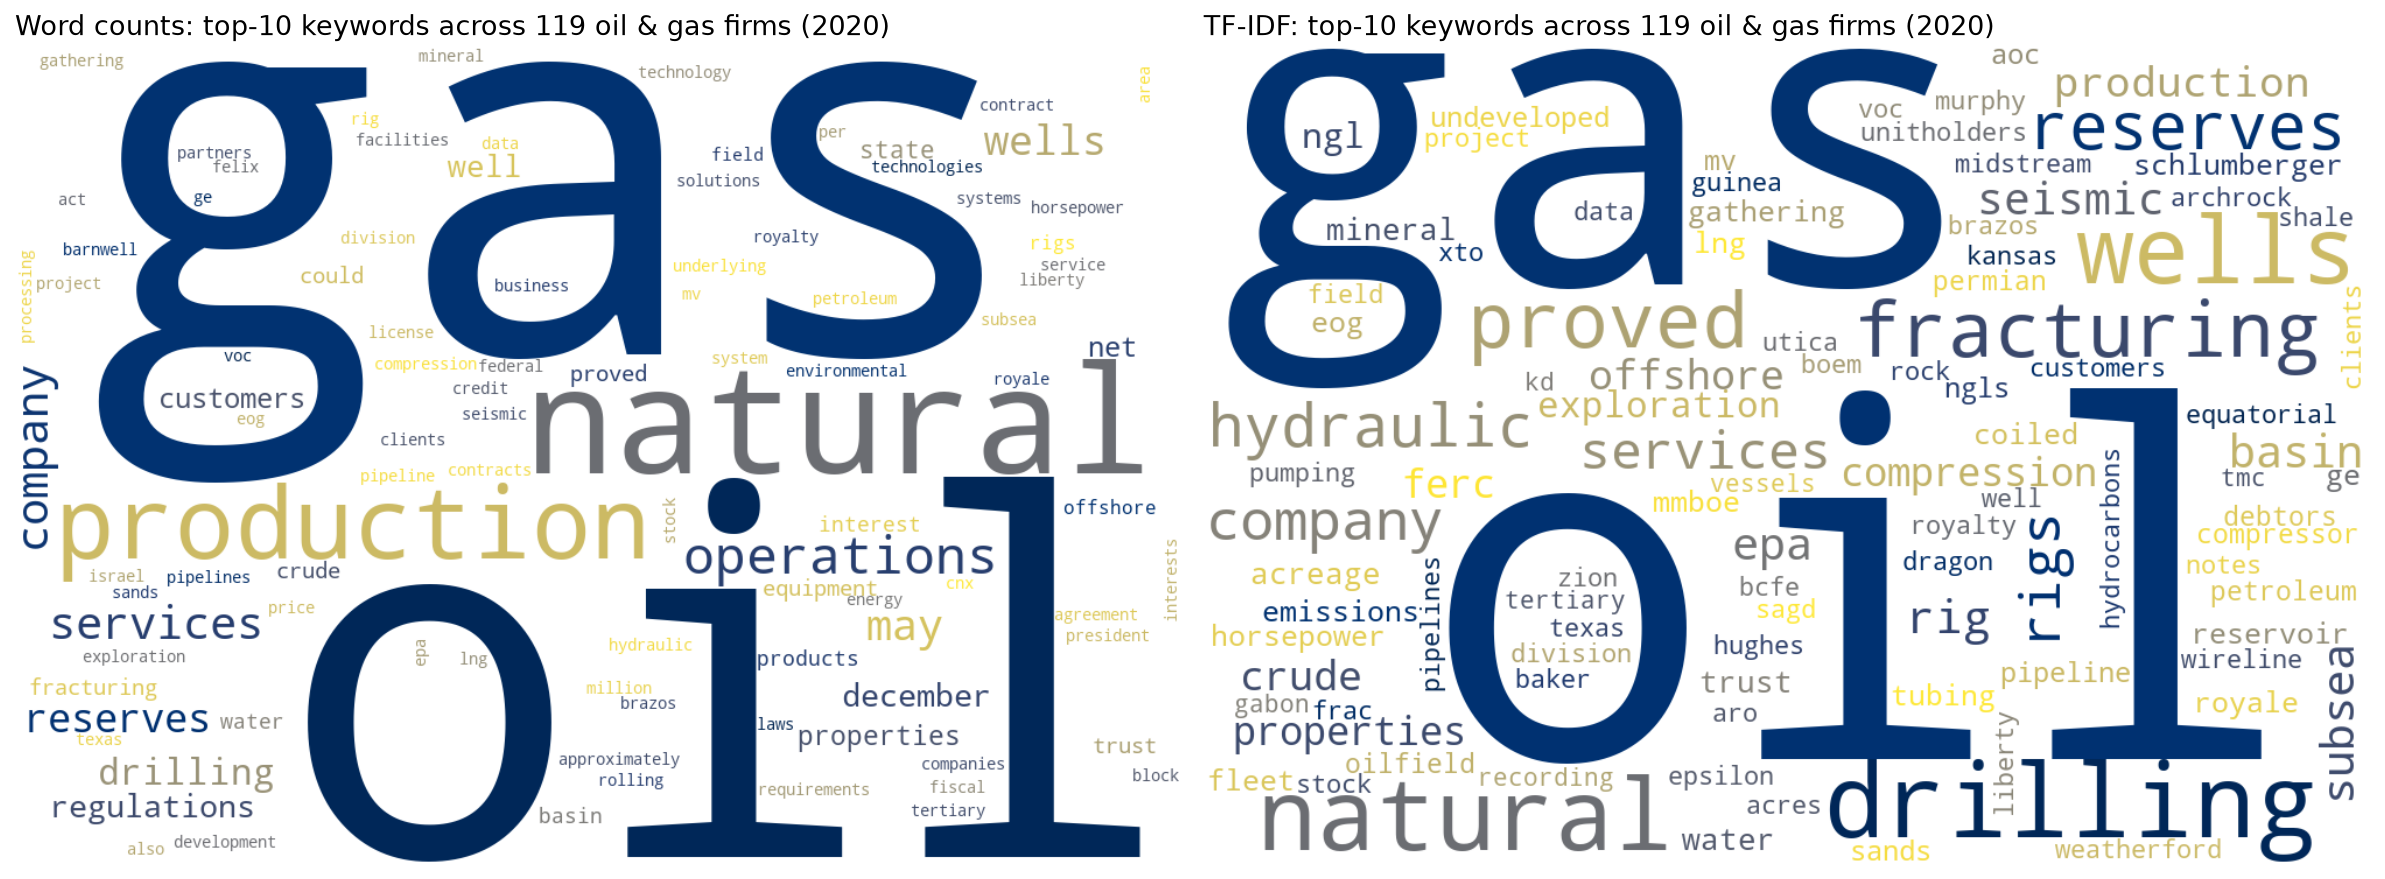

In [8]:
YEAR = 2020
SECTOR_CODES = [13]

df_text = pd.read_pickle(f"df_{YEAR}_clean.pkl")        # output of Part C
public_firms = pd.read_csv("public_firms.csv")
public_firms["major_group"] = public_firms["sic"] // 100

# ---------- D.1 Merge: one row per firm ----------
# Merge key = gvkey. It's Compustat's permanent firm ID and exists in both files.
# cik is less reliable here: in the 10-K file one cik maps to several gvkeys (e.g. Arconic),
# and company names are formatted differently ("DEVON ENERGY CORP/DE" vs "DEVON ENERGY CORP").
#
# public_firms has one row per firm-year, so collapse it to one row per firm first:
# keep the fiscal year closest to the filing year.
sector_firms = public_firms[public_firms["major_group"].isin(SECTOR_CODES)].copy()
sector_firms["year_gap"] = (sector_firms["fyear"] - YEAR).abs()
sector_firms = (sector_firms.sort_values(["gvkey", "year_gap"])
                .drop_duplicates("gvkey")
                [["gvkey", "conm", "sic", "fyear", "sale", "asset", "location"]])

df_og = df_text.merge(sector_firms, on="gvkey", how="inner")

# A few firms have 2+ different filings; keep the longest (the full Item 1, not a stub or amendment)
df_og = (df_og.assign(n_chars=df_og["item_1"].str.len())
         .sort_values("n_chars", ascending=False)
         .drop_duplicates("gvkey")
         .drop(columns="n_chars"))
print(f"Merged rows (one per firm): {len(df_og)}")
print(f"Firms whose kept row is fyear {YEAR}: {(df_og['fyear'] == YEAR).sum()}")

# ---------- Data quality: drop filings that contain another company's text ----------
# In the 2020 course file, ~1 in 4 oil & gas rows carries an unrelated firm's Item 1
# (e.g. "ConocoPhillips" -> SunPower, "Marathon Oil" -> Hershey). Test: does the firm's
# distinctive name word appear anywhere in its own Item 1? All flagged rows were read
# manually; Patterson-UTI is genuine drilling text that simply never names itself.
GENERIC_NAME_WORDS = {"inc", "corp", "co", "ltd", "lp", "the", "company", "energy", "resources",
                      "oil", "gas", "petroleum", "corporation", "group", "holdings", "plc", "de",
                      "international", "partners", "sa", "limited", "new", "trust", "royalty"}
MANUALLY_VERIFIED_OK = {"PATTERSON UTI ENERGY INC"}
# The name test misses firms whose name word is short or common ("SM", "Range", "Select").
# Second pass: every row with < 10 oil & gas words per 1,000 was read by hand; these three
# carry another company's text (Cleveland-Cliffs, Columbia Banking, Iridium). The other rows
# in that group not already caught (ENGlobal, Mission Mining) are genuine and kept.
MANUALLY_VERIFIED_BAD = {"SM Energy Co", "RANGE RESOURCES CORP", "Select Energy Services, Inc."}
OG_WORDS = r"\b(?:oil|gas|drilling|wells?|reserves|crude|petroleum|hydrocarbons?|oilfield|rigs?)\b"


def name_appears_in_text(name, text):
    words = [w for w in re.findall(r"[a-z]+", name.lower()) if w not in GENERIC_NAME_WORDS and len(w) > 2]
    return (not words) or (words[0] in text.lower())


df_og["og_words_per_1k"] = (df_og["item_1_clean"].str.count(OG_WORDS)
                            / df_og["item_1_clean"].str.split().str.len() * 1000)
print("Low-vocabulary rows for manual review:\n",
      df_og.loc[df_og["og_words_per_1k"] < 10, ["name", "og_words_per_1k"]].round(1).to_string())
df_og["text_matches_firm"] = [
    (name_appears_in_text(n, t) or n in MANUALLY_VERIFIED_OK) and n not in MANUALLY_VERIFIED_BAD
    for n, t in zip(df_og["name"], df_og["item_1"])]
dropped = df_og.loc[~df_og["text_matches_firm"], ["gvkey", "name"]].assign(
    text_starts_with=df_og["item_1"].str[:70])
dropped.to_csv(f"d_dropped_mismatched_{YEAR}.csv", index=False)   # appendix table for the report
df_all = df_og.copy()   # all merged firms, kept for the appendix below
df_og = df_og[df_og["text_matches_firm"]].reset_index(drop=True)
print(f"Dropped {len(dropped)} mismatched filings -> {len(df_og)} firms analysed")

# ---------- D.2 Top 10 keywords per firm ----------
# Letters-only tokens of 2+ chars: drops the numbers and stray single letters ("u s") that
# Part C deliberately kept, since they carry no meaning as keywords
TOKEN_PATTERN = r"(?u)\b[a-z][a-z]+\b"

count_vec = CountVectorizer(token_pattern=TOKEN_PATTERN)
count_matrix = count_vec.fit_transform(df_og["item_1_clean"])

# IDF is learned on the FULL 10-K corpus (all industries), not just oil & gas. That way a
# word scores high when it is frequent for this firm AND rare across US public companies,
# so the keywords say what makes an oil & gas business different. (Fitting IDF only within the sector
# would instead surface what separates one O&G firm from another: basins, firm names.)
# min_df=5 stops one-off typos from earning the maximum IDF.
tfidf_vec = TfidfVectorizer(token_pattern=TOKEN_PATTERN, min_df=5)
tfidf_vec.fit(df_text["item_1_clean"].drop_duplicates())
tfidf_matrix = tfidf_vec.transform(df_og["item_1_clean"])


def top_n_terms(matrix, vocab, n=10):
    rows = []
    for i in range(matrix.shape[0]):
        scores = matrix[i].toarray().ravel()
        top_idx = scores.argsort()[::-1][:n]
        rows.append([(vocab[j], scores[j]) for j in top_idx if scores[j] > 0])
    return rows


count_vocab = count_vec.get_feature_names_out()
tfidf_vocab = tfidf_vec.get_feature_names_out()
df_og["top10_count"] = top_n_terms(count_matrix, count_vocab)
df_og["top10_tfidf"] = top_n_terms(tfidf_matrix, tfidf_vocab)

keywords_table = df_og[["gvkey", "conm", "sic"]].assign(
    top10_count=df_og["top10_count"].map(lambda kw: ", ".join(w for w, _ in kw)),
    top10_tfidf=df_og["top10_tfidf"].map(lambda kw: ", ".join(w for w, _ in kw)))
keywords_table.to_csv(f"d_keywords_by_firm_{YEAR}.csv", index=False)
print("Top 10 keywords per firm (first 15 firms; the full table is in the CSV):")
display(keywords_table.head(15))
df_og.to_pickle(f"df_og_{YEAR}.pkl")   # reused in Part G (firm embeddings)

# ---------- D.3 Wordclouds across the sector ----------
# Weight = each keyword's score summed over every firm whose top 10 it appears in, so the
# clouds show exactly the D.2 keywords, sized by how strongly and how widely they recur.
def aggregate_keywords(keyword_lists):
    totals = {}
    for kw in keyword_lists:
        for word, score in kw:
            totals[word] = totals.get(word, 0) + score
    return pd.Series(totals).sort_values(ascending=False)


sector_counts = aggregate_keywords(df_og["top10_count"])
sector_tfidf = aggregate_keywords(df_og["top10_tfidf"])
print("Word count, sector top 20:\n", sector_counts.head(20).round(0).to_string())
print("TF-IDF, sector top 20:\n", sector_tfidf.head(20).round(2).to_string())

# How many firms each keyword is a top-10 term for (breadth, not size)
firm_freq = lambda lists: pd.Series([w for kw in lists for w, _ in kw]).value_counts()
print("Firms with term in top 10 (count):\n", firm_freq(df_og["top10_count"]).head(15).to_string())
print("Firms with term in top 10 (tfidf):\n", firm_freq(df_og["top10_tfidf"]).head(15).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, weights, title in [(axes[0], sector_counts, "Word counts"), (axes[1], sector_tfidf, "TF-IDF")]:
    wc = WordCloud(width=1000, height=700, background_color="white", colormap="cividis",
                   max_words=100, random_state=42, prefer_horizontal=0.95)
    ax.imshow(wc.generate_from_frequencies(weights.to_dict()), interpolation="bilinear")
    ax.set_title(f"{title}: top-10 keywords across {len(df_og)} oil & gas firms ({YEAR})",
                 loc="left", fontsize=13)
    ax.axis("off")
fig.tight_layout()
fig.savefig(f"d3_wordclouds_{YEAR}.png", dpi=150, bbox_inches="tight")

### E. Word embedding (word2vec, 2020 full sample)

We train gensim `Word2Vec` on the **full cleaned 2020 corpus (all 5,152 filings, all industries)**, as the brief requires.

**Settings:**
- **Skip-gram** (`sg=1`), which handles less frequent words like "emissions" better than CBOW.
- `vector_size=100`, `window=5`, `min_count=5`, `epochs=5`, `seed=42`.

**Sentences:** gensim ignores every token after the first 10,000 in a "sentence", and Item 1 sections run to 50,000+ tokens. Because Step C removed punctuation, we can't split on real sentences, so each filing is cut into **1,000-token chunks**. Bare numbers are dropped, and identical texts are used once.

**Keyword choice.** From the D.3 wordclouds, we chose three words that are clearly visible in the TF-IDF cloud and cover three different sides of the business:
- **drilling** (operations): a top-10 TF-IDF term for 54 firms.
- **reserves** (the asset base that underpins valuation): top-10 for 26 firms, alongside *proved*.
- **emissions** (environmental regulation): appears in the TF-IDF cloud, as does *epa*.

*Gensim prints `Exception ignored in 'our_dot_float'` warnings during training, likely due to a version mismatch with Python 3.14. We could not rule out an effect on training; the nearest-neighbour results below are consistent with domain knowledge, but should be read with that caveat.*

In [7]:
YEAR = 2020
KEYWORDS = ["drilling", "reserves", "emissions"]
CHUNK_SIZE = 1000


def build_sentences(df):
    # Identical texts filed under different CIKs (a quirk of the 2020 file) would be
    # counted twice, so train on each distinct text once
    texts = df["item_1_clean"].drop_duplicates()
    # gensim silently ignores everything after the first 10,000 tokens of a "sentence",
    # and the long 10-Ks run to 50k+ tokens. Part C removed punctuation, so we can't split
    # on real sentences; fixed 1,000-token chunks keep every word in training.
    sentences = []
    for text in texts:
        tokens = [t for t in text.split() if not t.isdigit()]   # bare numbers carry no meaning
        sentences += [tokens[i:i + CHUNK_SIZE] for i in range(0, len(tokens), CHUNK_SIZE)]
    return sentences


def train_word2vec(df):
    sentences = build_sentences(df)
    print(f"{len(sentences):,} chunks, {sum(map(len, sentences)):,} tokens")
    return Word2Vec(
        sentences,
        vector_size=100,   # gensim default; enough for a ~20M-token corpus
        window=5,          # local context: picks up near-synonyms rather than broad topic
        min_count=5,       # drop typos / one-off tokens, same idea as min_df=5 in Part D
        sg=1,              # skip-gram: better than CBOW for less frequent words like "emissions"
        epochs=5,
        seed=42,
        workers=4,         # note: exact reproducibility needs workers=1 (thread scheduling varies)
    )


def similar_words_table(model, keywords, topn=5):
    rows = []
    for kw in keywords:
        if kw not in model.wv:
            print(f"'{kw}' not in vocabulary")
            continue
        for rank, (word, score) in enumerate(model.wv.most_similar(kw, topn=topn), start=1):
            rows.append({"keyword": kw, "rank": rank, "similar_word": word, "cosine": round(score, 3)})
    return pd.DataFrame(rows)


if __name__ == "__main__":
    df_text = pd.read_pickle(f"df_{YEAR}_clean.pkl")      # output of Part C (full sample, all sectors)
    w2v_model = train_word2vec(df_text)
    w2v_model.save(f"w2v_{YEAR}.model")                   # reused in Part F (comparison) and G (firm embeddings)

    print(f"Vocabulary size: {len(w2v_model.wv):,}")
    similar = similar_words_table(w2v_model, KEYWORDS)
    similar.to_csv(f"e_similar_words_{YEAR}.csv", index=False)
    print(similar.pivot(index="rank", columns="keyword", values="similar_word"))
    print(similar.pivot(index="rank", columns="keyword", values="cosine"))

24,473 chunks, 22,216,462 tokens


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

Vocabulary size: 55,232
keyword     drilling   emissions reserves
rank                                     
1           workover         ghg   proved
2            drilled    emission     ibnr
3              wells  greenhouse     puds
4              drill        ghgs      pud
5        exploration         nox     mboe
keyword  drilling  emissions  reserves
rank                                  
1           0.808      0.933     0.828
2           0.797      0.898     0.744
3           0.796      0.886     0.732
4           0.793      0.857     0.731
5           0.777      0.836     0.727


In [8]:
for kw in ["drilling", "reserves", "emissions"]:
    print(kw, [w for w, _ in w2v_model.wv.most_similar(kw, topn=15)])

for a, b in [("emissions", "methane"), ("emissions", "targets"), ("emissions", "capture"),
             ("reserves", "shareholders"), ("drilling", "discipline")]:
    if a in w2v_model.wv and b in w2v_model.wv:
        print(a, b, round(w2v_model.wv.similarity(a, b), 3))

drilling ['workover', 'drilled', 'wells', 'drill', 'exploration', 'rig', 'wellbore', 'rigs', 'recompletion', 'recompletions', 'acidizing', 'workovers', 'seismic', 'completions', 'horizontal']
reserves ['proved', 'ibnr', 'puds', 'pud', 'mboe', 'lae', 'undiscounted', 'recoverable', 'unproved', 'undeveloped', 'tcfe', 'bcfe', 'mmboe', 'mmbo', 'hpg']
emissions ['ghg', 'emission', 'greenhouse', 'ghgs', 'nox', 'methane', 'dioxide', 'pollutants', 'so2', 'tailpipe', 'toxics', 'caa', 'gases', 'haps', 'mercury']
emissions methane 0.835
emissions targets 0.324
emissions capture 0.325
reserves shareholders 0.297
drilling discipline 0.199


### F. Comparative analysis: 2020 vs 2025

We repeat Steps C–E for both years with the same code, so the two years are processed identically:
- clean the text;
- merge on `gvkey`, keeping the firm-year closest to each filing year;
- apply the mismatch screen, which now also drops filings under 200 words (stubs that only say "incorporated by reference");
- compute keywords;
- train a separate word2vec model per year.

Two design choices keep the comparison fair:
- **Keyword comparison:** summed TF-IDF scores are not comparable across years, because firm counts differ and the IDF is fitted per year. We compare the **share of firms that have each word in their top-10 TF-IDF keywords** instead.
- **Word2vec comparison:** the two models are trained separately, so their cosine scores are on different scales. We compare **which words are neighbours**, not the scores.

In [13]:
STOP_WORDS = set(stopwords.words("english"))
YEARS = [2020, 2025]

public_firms = pd.read_csv("public_firms.csv")
public_firms["major_group"] = public_firms["sic"] // 100

In [14]:
def clean_text(text):
    text = re.sub(r"[^\w\s]|_", " ", text.lower())
    return " ".join(w for w in text.split() if w not in STOP_WORDS)


df_text = {}
for year in YEARS:
    df = pd.read_csv(f"{year}_10K_item1_full.csv").drop_duplicates()   # 2020 has 329 exact duplicate rows
    df["item_1_clean"] = df["item_1"].fillna("").map(clean_text)
    df_text[year] = df
    print(year, df.shape)

2020 (5152, 6)
2025 (4536, 6)


In [15]:
GENERIC_WORDS = {"inc", "corp", "co", "ltd", "lp", "the", "company", "energy", "resources", "oil", "gas",
                 "petroleum", "corporation", "group", "holdings", "plc", "de", "international",
                 "partners", "sa", "limited", "new", "trust", "royalty"}
GENUINE = {(2020, "PATTERSON UTI ENERGY INC"), (2025, "PATTERSON UTI ENERGY INC"),
           (2025, "NORTHERN OIL & GAS, INC."), (2025, "GULF ISLAND FABRICATION INC")}
MISLABELLED = {(2020, "SM Energy Co"), (2020, "RANGE RESOURCES CORP"), (2020, "Select Energy Services, Inc.")}


def is_valid_filing(year, name, text):
    if len(text.split()) < 200 or (year, name) in MISLABELLED:   # <200 words = "incorporated by reference" stub
        return False
    if (year, name) in GENUINE:
        return True
    name_words = [w for w in re.findall(r"[a-z]+", name.lower()) if w not in GENERIC_WORDS and len(w) > 2]
    return not name_words or name_words[0] in text.lower()


def top_10(matrix, vocab):
    keywords = []
    for i in range(matrix.shape[0]):
        scores = matrix[i].toarray().ravel()
        keywords.append([(vocab[j], scores[j]) for j in scores.argsort()[::-1][:10]])
    return keywords


df_og = {}
for year in YEARS:
    # one row per firm: the firm-year closest to the filing year; merge key = gvkey
    firms = public_firms[public_firms["major_group"] == 13].copy()
    firms["gap"] = (firms["fyear"] - year).abs()
    firms = firms.sort_values(["gvkey", "gap"]).drop_duplicates("gvkey")[["gvkey", "conm", "sic"]]

    df = df_text[year].merge(firms, on="gvkey", how="inner")
    df = df.loc[df["item_1"].str.len().sort_values(ascending=False).index].drop_duplicates("gvkey")
    valid = [is_valid_filing(year, n, t) for n, t in zip(df["name"], df["item_1"])]
    df = df[valid].reset_index(drop=True)

    # letters-only tokens; TF-IDF's IDF learned on all industries so oil & gas terms stand out
    token_pattern = r"(?u)\b[a-z][a-z]+\b"
    count_vec = CountVectorizer(token_pattern=token_pattern)
    count_matrix = count_vec.fit_transform(df["item_1_clean"])
    tfidf_vec = TfidfVectorizer(token_pattern=token_pattern, min_df=5).fit(df_text[year]["item_1_clean"].drop_duplicates())
    tfidf_matrix = tfidf_vec.transform(df["item_1_clean"])

    df["top10_count"] = top_10(count_matrix, count_vec.get_feature_names_out())
    df["top10_tfidf"] = top_10(tfidf_matrix, tfidf_vec.get_feature_names_out())
    df_og[year] = df
    print(f"{year}: {len(valid)} merged, {sum(valid)} valid filings")

2020: 159 merged, 119 valid filings
2025: 88 merged, 85 valid filings


### F.3 Compare keywords and wordclouds

Biggest falls:
            2020   2025  change
oil       0.874  0.765  -0.109
company   0.126  0.024  -0.103
drilling  0.454  0.353  -0.101
coiled    0.042  0.000  -0.042
ferc      0.084  0.047  -0.037
fleet     0.059  0.024  -0.035
well      0.034  0.000  -0.034
ngl       0.067  0.035  -0.032

Biggest rises:
             2020   2025  change
sand       0.008  0.047   0.039
energy     0.017  0.059   0.042
crude      0.050  0.094   0.044
proved     0.286  0.329   0.044
proppant   0.000  0.047   0.047
offshore   0.076  0.141   0.066
emissions  0.059  0.141   0.082
reserves   0.218  0.306   0.087


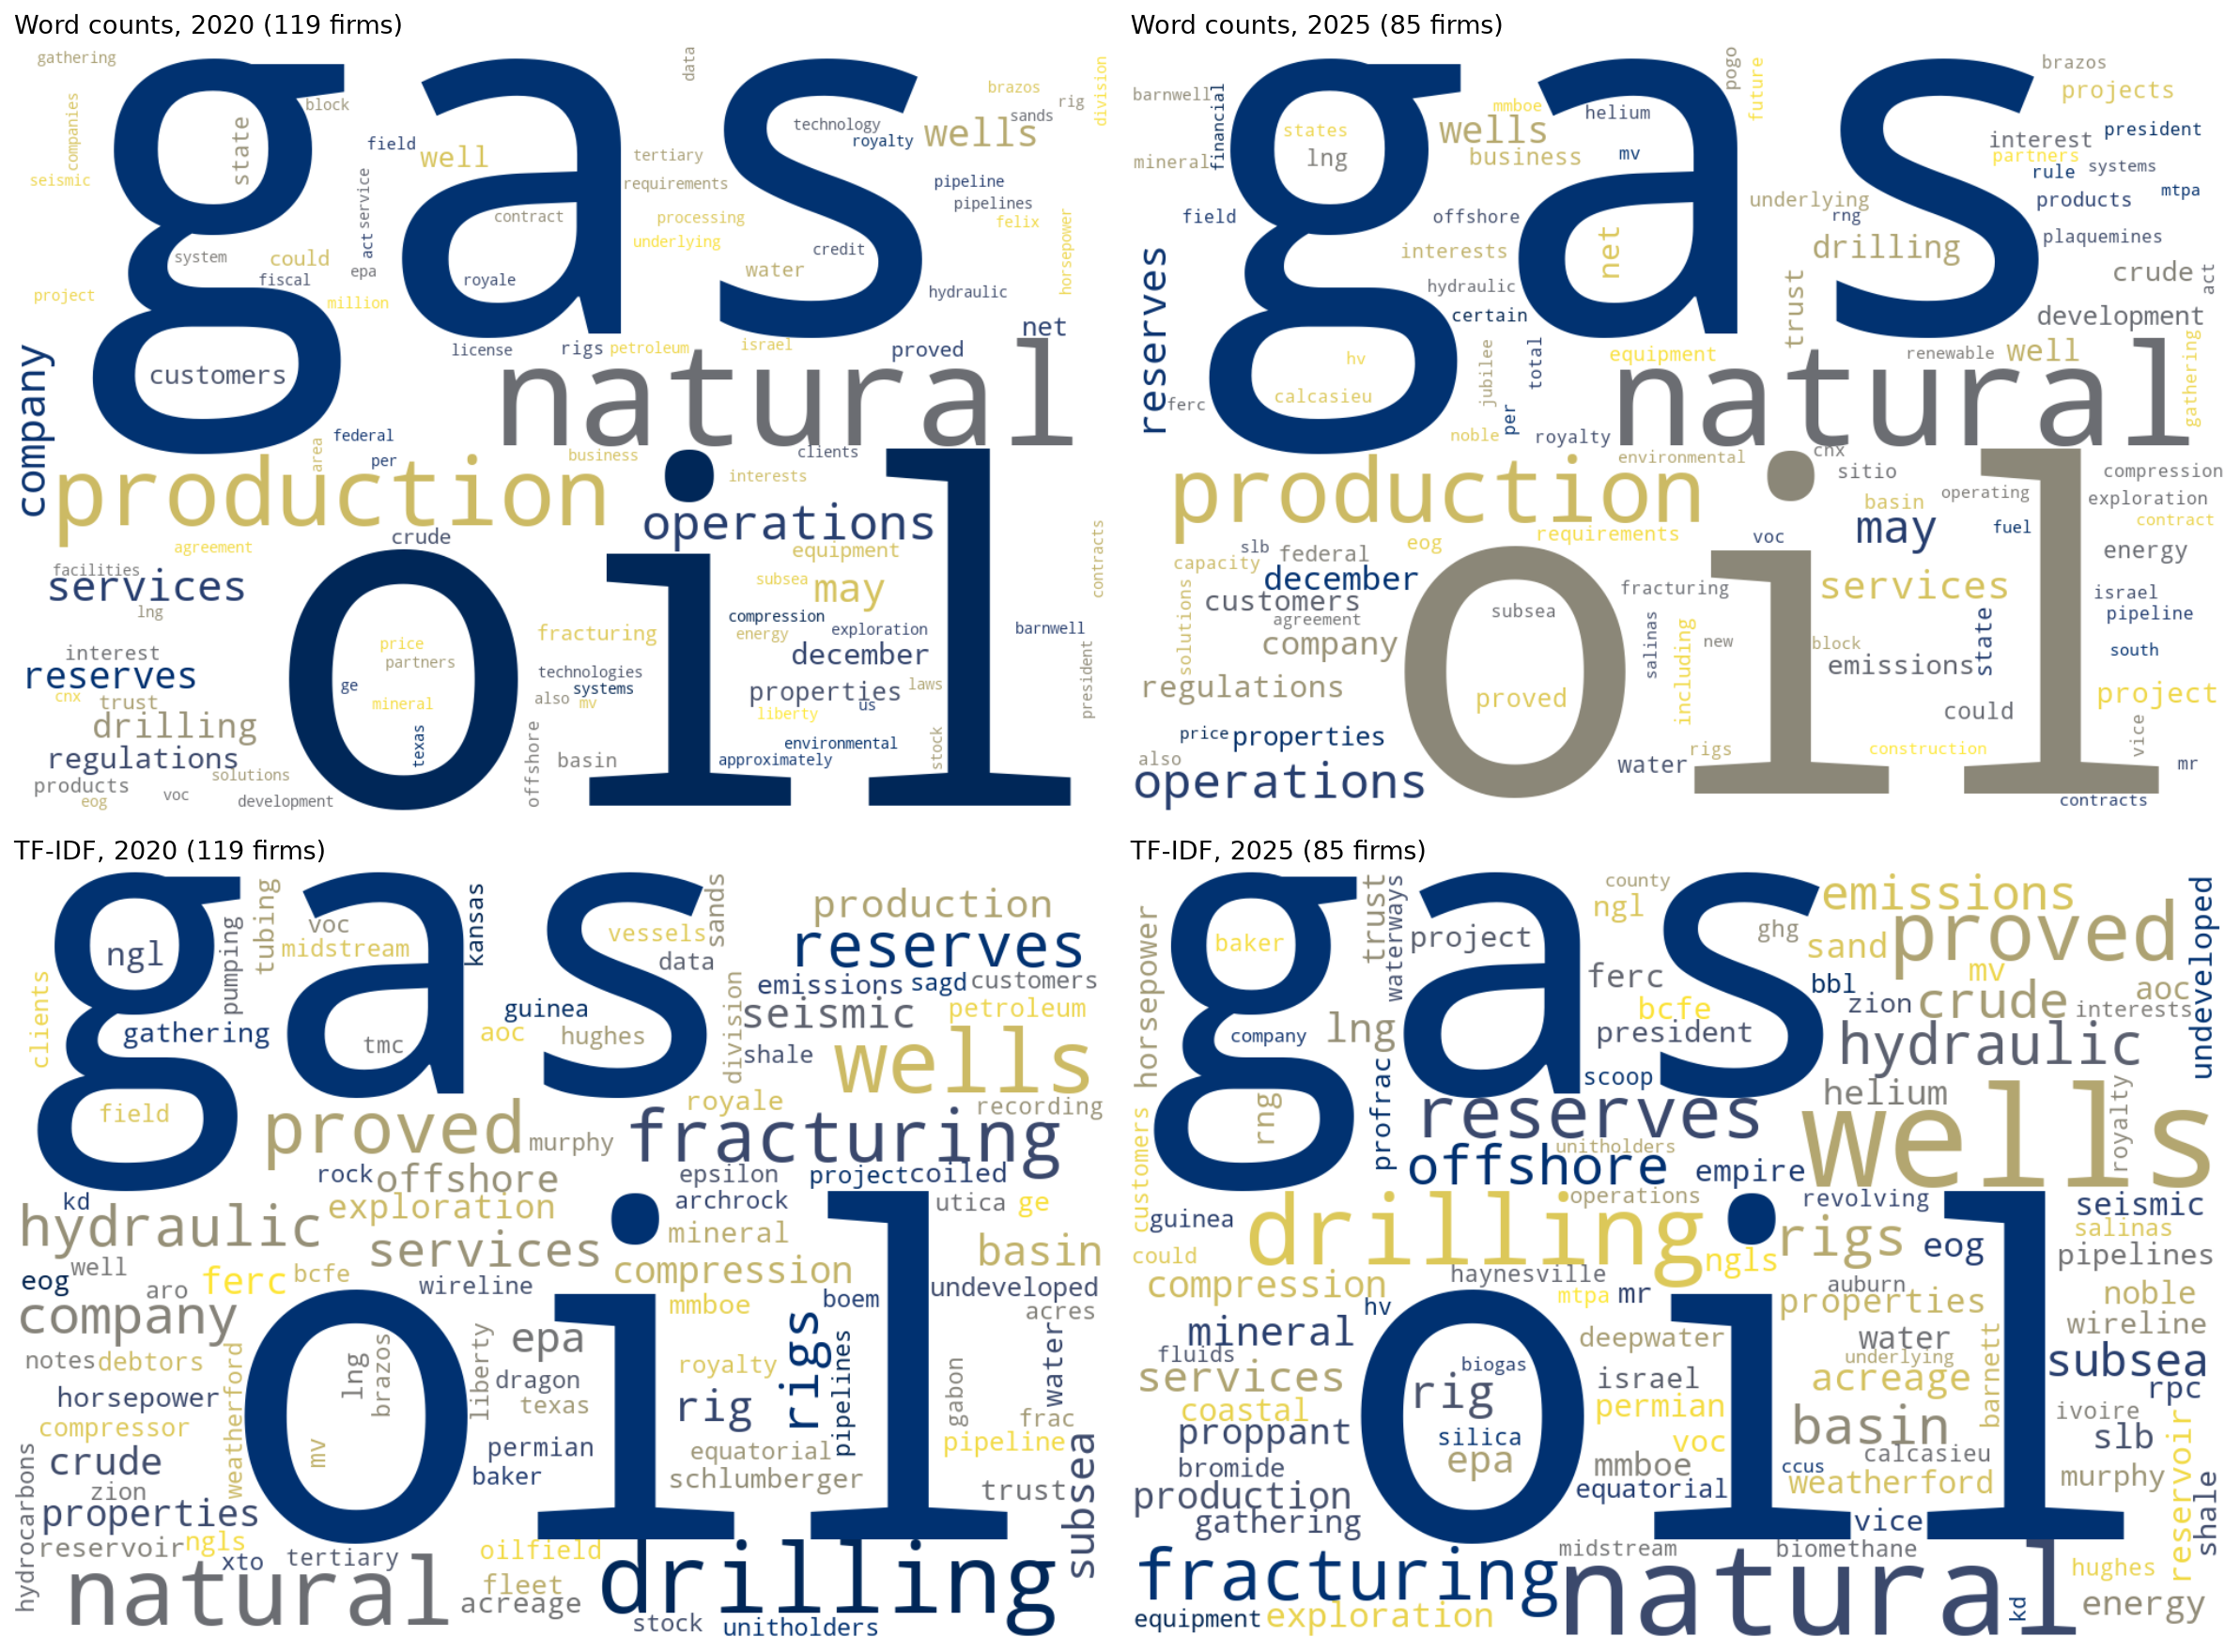

In [16]:
# Summed TF-IDF isn't comparable across years (different firm counts, IDF fit per year),
# so compare the share of firms that have each word in their top 10
def top10_share(df, col):
    return pd.Series([w for kw in df[col] for w, _ in kw]).value_counts() / len(df)


keyword_shift = pd.DataFrame({y: top10_share(df_og[y], "top10_tfidf") for y in YEARS}).fillna(0)
keyword_shift["change"] = keyword_shift[2025] - keyword_shift[2020]
keyword_shift = keyword_shift.sort_values("change")
print("Biggest falls:\n", keyword_shift.head(8).round(3))
print("\nBiggest rises:\n", keyword_shift.tail(8).round(3))


def keyword_weights(df, col):
    weights = {}
    for kw in df[col]:
        for word, score in kw:
            weights[word] = weights.get(word, 0) + score
    return weights


fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for row, col, label in [(0, "top10_count", "Word counts"), (1, "top10_tfidf", "TF-IDF")]:
    for ax, year in zip(axes[row], YEARS):
        cloud = WordCloud(width=1000, height=700, background_color="white", colormap="cividis",
                          max_words=100, random_state=42).generate_from_frequencies(keyword_weights(df_og[year], col))
        ax.imshow(cloud, interpolation="bilinear")
        ax.set_title(f"{label}, {year} ({len(df_og[year])} firms)", loc="left", fontsize=13)
        ax.axis("off")
plt.tight_layout()
plt.savefig("f_wordclouds_2020_vs_2025.png", dpi=150)
plt.show()

### F.4 Step E for both years: word2vec and nearest neighbours 

In [17]:
# gensim ignores tokens past 10,000 per sentence, so long filings are split into 1,000-word chunks
def to_sentences(texts, size=1000):
    sentences = []
    for text in texts.drop_duplicates():
        tokens = [t for t in text.split() if not t.isdigit()]
        sentences += [tokens[i:i + size] for i in range(0, len(tokens), size)]
    return sentences


KEYWORDS = ["drilling", "reserves", "emissions"]
w2v_models = {}
for year in YEARS:
    w2v_models[year] = Word2Vec(to_sentences(df_text[year]["item_1_clean"]), vector_size=100, window=5,
                                min_count=5, sg=1, epochs=5, seed=42, workers=4)

# The two models are trained separately, so their cosine scores aren't on the same scale:
# compare which words are neighbours, not the numbers
for kw in KEYWORDS:
    neighbours = pd.DataFrame({year: [f"{w} ({s:.2f})" for w, s in w2v_models[year].wv.most_similar(kw, topn=10)]
                               for year in YEARS}, index=range(1, 11))
    print(f"\n=== {kw} ===\n{neighbours}")

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl


=== drilling ===
                   2020                 2025
1        drilled (0.80)         drill (0.79)
2          drill (0.80)   exploration (0.78)
3       workover (0.80)  recompletion (0.77)
4          wells (0.79)         wells (0.76)
5    exploration (0.78)   completions (0.76)
6            rig (0.76)      workover (0.76)
7       wellbore (0.76)     workovers (0.73)
8   recompletion (0.76)     acidizing (0.73)
9     horizontal (0.75)       drilled (0.73)
10   completions (0.75)      wellbore (0.72)

=== reserves ===
                   2020                2025
1         proved (0.81)       proved (0.81)
2           ibnr (0.75)         pdnp (0.75)
3            pud (0.75)         ibnr (0.73)
4           puds (0.74)         tcfe (0.73)
5       unproved (0.73)    undrilled (0.72)
6           mboe (0.72)  undeveloped (0.72)
7   undiscounted (0.72)  recoverable (0.71)
8    undeveloped (0.72)          pud (0.71)
9            lae (0.71)         mboe (0.70)
10   recoverable (0.71)      

### F.5 What changed between 2020 and 2025, and why

**1. Less about drilling, more about reserves.** "drilling" is a top-10 TF-IDF term for 45% of firms in 2020 and 35% in 2025, and "oil" falls from 87% to 77%. Meanwhile "reserves" rises from 22% to 31% and "proved" from 29% to 33%. After the 2020 price collapse, producers shifted from growth through drilling to capital discipline and returns to shareholders. Their filings put more emphasis on the value of the reserves they already hold than on drilling activity.

**2. Emissions became a mainstream topic.** "emissions" grows from 6% to 14% of firms. In word2vec, *methane* moves from 6th to 4th among the closest words, and *co2* and *carbon* enter the top 10 in 2025. Stricter methane regulation and investor and regulator demands for climate disclosure likely pushed emissions language into the business description itself.

**3. Completion technology.** "proppant" (0% → 5%) and "sand" (1% → 5%) appear among top keywords. In word2vec, *recompletion* (8th → 3rd) and *completions* (10th → 5th) move closer to "drilling". This is consistent with the industry getting more output from each well through completion design.

**4. Reserves vocabulary becomes more technical.** In 2025, "reserves" picks up neighbours such as *pdnp* (proved developed non-producing), *undrilled* and *tcfe*. These terms describe reserve categories in more detail, in line with the greater focus on reserves.

**Caveats.** The sample shrinks from 119 to 85 firms, partly through mergers and firms leaving the market, so some of these shifts reflect which firms are included rather than changes in what firms say. The two word2vec models were trained separately, so we compare which words are neighbours, not the similarity scores.

## Part 3 — Firm analysis: EOG Resources

**Why EOG:** EOG had the third-highest 2025 sales ($22.6B) among US SIC 1311 firms, behind ConocoPhillips and Enterprise Products (a pipeline business). Among the oil and gas producers in our peer set it ranks second, after ConocoPhillips. It has also been present for all 32 years of the dataset, which allows a long comparison.

**Direction:** we compare EOG's **revenue, market share and ROA** with its competitors (the brief's second suggested direction).

**Peer group:** the 10 largest US SIC 1311 producers by 2025 sales. We exclude Enterprise Products (pipelines), Cheniere and Venture Global (LNG export): they share the SIC code but run different businesses.

**Market share** = EOG's sales / total sales of all US SIC 1311 firms in the dataset. It is a share of listed-producer revenue, not of national oil & gas output.

### G.1 Load data and define the peer group

In [10]:
public_firms = pd.read_csv("public_firms.csv")

# Universe for market share: US crude & natural gas producers (SIC 1311)
producers = public_firms[(public_firms["sic"] == 1311) & (public_firms["location"] == "USA")
                         & (public_firms["asset"] > 0)].copy()
producers["roa"] = producers["net_income"] / producers["asset"]

# Peers: the largest US producers by 2025 sales. Enterprise Products (pipelines) and
# Cheniere / Venture Global (LNG export) carry SIC 1311 but run different businesses, so they're excluded.
PEERS = {"EOG RESOURCES INC": "EOG", "CONOCOPHILLIPS": "ConocoPhillips", "OCCIDENTAL PETROLEUM CORP": "Occidental",
         "DEVON ENERGY CORP": "Devon", "DIAMONDBACK ENERGY INC": "Diamondback", "EXPAND ENERGY CORP": "Expand",
         "COTERRA ENERGY INC": "Coterra", "APA CORP": "APA", "OVINTIV INC": "Ovintiv", "EQT CORP": "EQT"}
peers = producers[producers["conm"].isin(PEERS) & (producers["fyear"] >= 2015)].copy()
peers["firm"] = peers["conm"].map(PEERS)

In [11]:
sales = peers.pivot_table(index="fyear", columns="firm", values="sale")
roa = peers.pivot_table(index="fyear", columns="firm", values="roa")
market_share = sales.div(producers.groupby("fyear")["sale"].sum(), axis=0)

others = peers[peers["firm"] != "EOG"]
summary = pd.DataFrame({
    "EOG sales ($M)": sales["EOG"],
    "EOG market share": market_share["EOG"],
    "EOG ROA": roa["EOG"],
    # median = typical peer; pooled = peer group's total net income / total assets
    "Peer median ROA": others.groupby("fyear")["roa"].median(),
    "Peer pooled ROA": others.groupby("fyear")["net_income"].sum() / others.groupby("fyear")["asset"].sum(),
    "EOG ROA rank (of 10)": roa.rank(axis=1, ascending=False)["EOG"],
})
summary["EOG premium vs median"] = summary["EOG ROA"] - summary["Peer median ROA"]
summary = summary.loc[2015:]
print(summary.round(3))

       EOG sales ($M)  EOG market share  EOG ROA  Peer median ROA  \
fyear                                                               
2015         8718.317             0.040   -0.168           -0.200   
2016         7363.394             0.042   -0.037           -0.062   
2017        11225.806             0.047    0.087            0.051   
2018        17011.202             0.060    0.101            0.080   
2019        17122.002             0.069    0.074           -0.006   
2020        11017.977             0.065   -0.017           -0.256   
2021        18517.000             0.063    0.122            0.089   
2022        25510.000             0.054    0.188            0.202   
2023        24000.000             0.067    0.173            0.108   
2024        23582.000             0.074    0.136            0.050   
2025        22595.000             0.069    0.096            0.064   

       Peer pooled ROA  EOG ROA rank (of 10)  EOG premium vs median  
fyear                           

In [12]:
growth = pd.DataFrame({
    "Asset growth 2019-25": peers[peers["fyear"] == 2025].set_index("firm")["asset"]
                            / peers[peers["fyear"] == 2019].set_index("firm")["asset"] - 1,
    "Sales growth 2019-25": sales.loc[2025] / sales.loc[2019] - 1,
    "ROA 2025": roa.loc[2025],
    "Avg ROA 2023-25": roa.loc[2023:2025].mean(),
}).sort_values("Asset growth 2019-25", ascending=False)
print(growth.round(3))
print("\nCorrelation, asset growth vs avg ROA 2023-25 (n=10):",
      round(growth["Asset growth 2019-25"].corr(growth["Avg ROA 2023-25"]), 2))
eog = peers[peers["firm"] == "EOG"].set_index("fyear").loc[[2024, 2025], ["sale", "asset", "net_income"]]
print("\nEOG, 2024 vs 2025 ($M):")
print(eog)
print((eog.loc[2025] / eog.loc[2024] - 1).round(3).rename("change 2024-25"))

                Asset growth 2019-25  Sales growth 2019-25  ROA 2025  \
firm                                                                   
Coterra                        4.402                 2.700     0.071   
Diamondback                    2.020                 2.791     0.023   
Devon                          1.304                 1.763     0.084   
EQT                            1.222                 0.957     0.049   
Expand                         0.747                 0.436     0.064   
ConocoPhillips                 0.729                 0.810     0.066   
EOG                            0.395                 0.320     0.096   
APA                           -0.019                 0.412     0.081   
Ovintiv                       -0.051                 0.324     0.061   
Occidental                    -0.230                 0.059     0.028   

                Avg ROA 2023-25  
firm                             
Coterra                   0.067  
Diamondback               0.060  

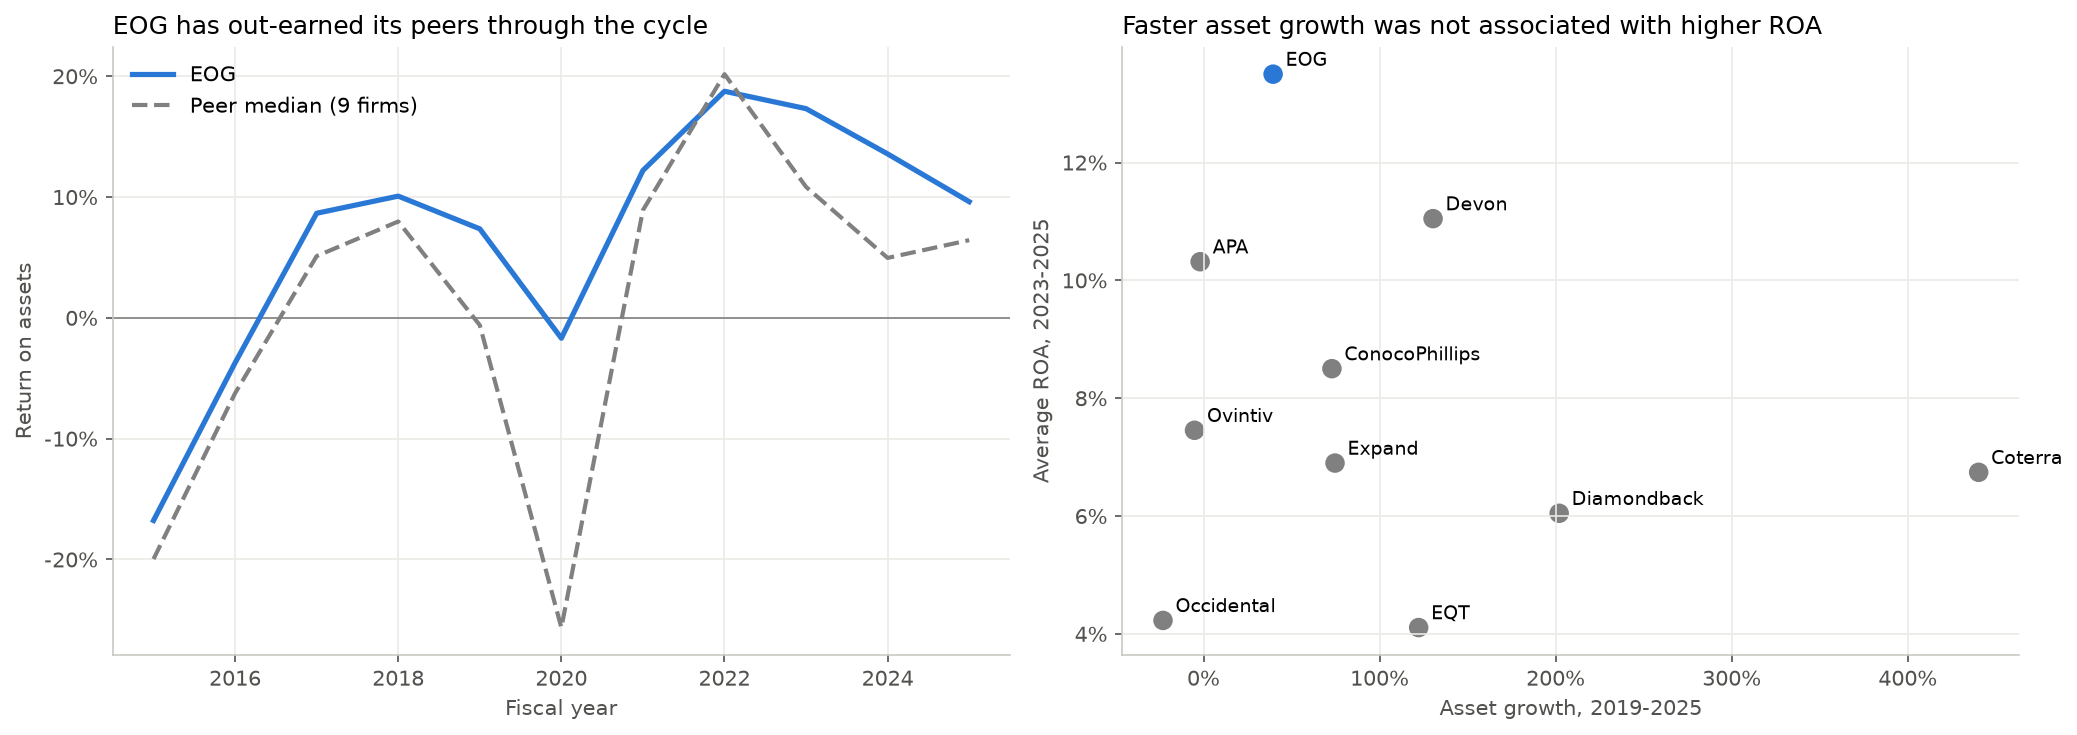

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.axhline(0, color="grey", linewidth=0.8)
ax.plot(summary.index, summary["EOG ROA"], color="#2a78d6", linewidth=2.5, label="EOG")
ax.plot(summary.index, summary["Peer median ROA"], color="grey", linewidth=2, linestyle="--", label="Peer median (9 firms)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_title("EOG has out-earned its peers through the cycle", loc="left")
ax.set_xlabel("Fiscal year")
ax.set_ylabel("Return on assets")
ax.legend(frameon=False)

ax = axes[1]
ax.scatter(growth["Asset growth 2019-25"], growth["Avg ROA 2023-25"],
           color=["#2a78d6" if f == "EOG" else "grey" for f in growth.index], s=70)
for firm, row in growth.iterrows():
    ax.annotate(firm, (row["Asset growth 2019-25"], row["Avg ROA 2023-25"]), xytext=(6, 4),
                textcoords="offset points", fontsize=9)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_title("Faster asset growth was not associated with higher ROA", loc="left")
ax.set_xlabel("Asset growth, 2019-2025")
ax.set_ylabel("Average ROA, 2023-2025")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("g_eog_vs_peers.png", dpi=150)
plt.show()

 Recommendation for EOG

**Put an explicit return hurdle on balance-sheet growth: new acquisitions and major capital programmes should be expected to earn at least EOG's own 2023–25 average ROA (about 13.5%) before they are approved.**

**Why**
1. EOG's advantage comes from **returns, not size**. It beat the peer median ROA in 10 of 11 years and led the group in 2024–25 while growing assets more slowly than most peers (B6 and the tables above).
2. That advantage is **eroding**. ROA fell from 18.8% to 9.6% over 2022–25, and in 2025 assets grew 9.8% while sales and net income fell. Recent capital is not yet earning at EOG's historical level.
3. Peers that grew assets fastest did not earn more (Coterra, Diamondback, EQT). Chasing scale through acquisitions is therefore not a proven route to better returns in this group.

A return hurdle protects the advantage that set EOG apart in the 2020 downturn, and makes clear to investors why recent asset growth should translate into earnings.

**Caveats.** ROA uses year-end book assets and GAAP net income, so impairments and acquisition accounting can move it sharply. Commodity prices drive most year-to-year swings for every producer. The peer group is small (10 firms), and the growth–ROA relationship is weak (r = −0.17), so this is a judgement supported by the evidence, not a statistical proof.